In [1]:
# Day 29: Student Performance Prediction System
# Objective: Validate and prepare student input features

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

print("=" * 60)
print("STUDENT PERFORMANCE PREDICTION SYSTEM")
print("DAY 29 - DATA QUALITY CHECK")
print("=" * 60)

print("\nLibraries imported successfully!")
print("Today's objective: Validate the cleaned student dataset.")

STUDENT PERFORMANCE PREDICTION SYSTEM
DAY 29 - DATA QUALITY CHECK

Libraries imported successfully!
Today's objective: Validate the cleaned student dataset.


In [2]:
# Cell 2: Load Cleaned Student Features

current_dir = Path.cwd()

possible_paths = [
    current_dir / "day28_cleaned_student_features.csv",
    current_dir.parent / "day28_cleaned_student_features.csv",
    current_dir.parent.parent / "day28_cleaned_student_features.csv",
]

dataset_path = next(
    (path for path in possible_paths if path.exists()),
    None
)

if dataset_path is not None:
    df = pd.read_csv(dataset_path)

    print("Cleaned dataset loaded successfully!")
    print("Dataset path:", dataset_path.resolve())
    print("Dataset shape:", df.shape)

    print("\nFirst 5 Records:")
    display(df.head())

else:
    print("Cleaned dataset file not found.")
    print("Current working directory:", current_dir)
    print("Please check the location of day28_cleaned_student_features.csv")

Cleaned dataset loaded successfully!
Dataset path: C:\Users\Bagmita\OneDrive\Desktop\Project\day28_cleaned_student_features.csv
Dataset shape: (3, 4)

First 5 Records:


,study_hours,attendance,previous_score,assignments_completed
0,6.4,91.0,57.6,8.71
1,4.2,85.5,37.8,8.82
2,4.8,87.0,43.2,8.51


In [3]:
# Cell 3: Check Dataset Structure

if "df" in globals() and not df.empty:
    print("=" * 50)
    print("DAY 29 - DATASET STRUCTURE")
    print("=" * 50)

    print("\n1. Dataset Dimensions")
    print("Rows:", df.shape[0])
    print("Columns:", df.shape[1])

    print("\n2. Column Names")
    print(df.columns.tolist())

    print("\n3. Data Types")
    display(df.dtypes.to_frame(name="Data Type"))

    print("\n4. Dataset Information")
    df.info()

    print("\n5. First 5 Records")
    display(df.head())

else:
    print("Dataset is empty or not loaded.")
    print("Please run Cell 2 first.")

DAY 29 - DATASET STRUCTURE

1. Dataset Dimensions
Rows: 3
Columns: 4

2. Column Names
['study_hours', 'attendance', 'previous_score', 'assignments_completed']

3. Data Types


,Data Type
study_hours,float64
attendance,float64
previous_score,float64
assignments_completed,float64



4. Dataset Information
<class 'pandas.DataFrame'>
RangeIndex: 3 entries, 0 to 2
Data columns (total 4 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   study_hours            3 non-null      float64
 1   attendance             3 non-null      float64
 2   previous_score         3 non-null      float64
 3   assignments_completed  3 non-null      float64
dtypes: float64(4)
memory usage: 228.0 bytes

5. First 5 Records


,study_hours,attendance,previous_score,assignments_completed
0,6.4,91.0,57.6,8.71
1,4.2,85.5,37.8,8.82
2,4.8,87.0,43.2,8.51


In [4]:
# Cell 4: Check Missing Values

if "df" in globals() and not df.empty:
    print("=" * 50)
    print("MISSING VALUE ANALYSIS")
    print("=" * 50)

    missing_counts = df.isnull().sum()
    missing_percentage = (missing_counts / len(df)) * 100

    missing_summary = pd.DataFrame({
        "Missing Values": missing_counts,
        "Missing Percentage": missing_percentage.round(2)
    })

    display(missing_summary)

    total_missing = int(missing_counts.sum())

    print("\nTotal Missing Values:", total_missing)

    if total_missing == 0:
        print("All columns are free from missing values.")
    else:
        print("Missing values detected. Further cleaning may be required.")

else:
    print("Dataset is empty or not loaded. Please run Cell 2 first.")

MISSING VALUE ANALYSIS


,Missing Values,Missing Percentage
study_hours,0,0.0
attendance,0,0.0
previous_score,0,0.0
assignments_completed,0,0.0



Total Missing Values: 0
All columns are free from missing values.


In [5]:
# Cell 5: Detect Duplicate Records

if "df" in globals() and not df.empty:
    print("=" * 50)
    print("DUPLICATE RECORD ANALYSIS")
    print("=" * 50)

    duplicate_count = int(df.duplicated().sum())

    print("Total Records:", len(df))
    print("Duplicate Records:", duplicate_count)
    print("Unique Records:", len(df.drop_duplicates()))

    if duplicate_count > 0:
        print("\nDuplicate records detected.")

        print("\nDuplicate Record Preview:")
        display(df[df.duplicated(keep=False)].head(10))

        # Create a separate dataset without exact duplicate rows
        df_unique = df.drop_duplicates().reset_index(drop=True)

        print("\nDataset after removing exact duplicates:")
        print("Original shape:", df.shape)
        print("Updated shape:", df_unique.shape)

    else:
        df_unique = df.copy()

        print("\nNo exact duplicate records found.")
        print("Dataset is ready for the next quality check.")

else:
    print("Dataset is empty or not loaded. Please run Cell 2 first.")

DUPLICATE RECORD ANALYSIS
Total Records: 3
Duplicate Records: 0
Unique Records: 3

No exact duplicate records found.
Dataset is ready for the next quality check.


In [6]:
# Cell 6: Validate Numeric Input Features

if "df_unique" in globals() and not df_unique.empty:

    expected_features = [
        "study_hours",
        "attendance",
        "previous_score",
        "assignments_completed"
    ]

    available_features = [
        col for col in expected_features
        if col in df_unique.columns
    ]

    missing_features = [
        col for col in expected_features
        if col not in df_unique.columns
    ]

    print("=" * 55)
    print("NUMERIC INPUT FEATURE VALIDATION")
    print("=" * 55)

    if missing_features:
        print("Missing expected features:", missing_features)

    if available_features:
        X_validation = df_unique[available_features].copy()

        for col in available_features:
            X_validation[col] = pd.to_numeric(
                X_validation[col],
                errors="coerce"
            )

        validation_summary = pd.DataFrame({
            "Data Type": X_validation.dtypes.astype(str),
            "Missing Values": X_validation.isnull().sum(),
            "Unique Values": X_validation.nunique(dropna=True)
        })

        display(validation_summary)

        print("\nNumeric Feature Statistics:")
        display(X_validation.describe().round(2))

        print("\nFeature validation completed.")

    else:
        print("No expected input features were found.")

else:
    print("df_unique is not available. Please run Cell 5 first.")

NUMERIC INPUT FEATURE VALIDATION


,Data Type,Missing Values,Unique Values
study_hours,float64,0,3
attendance,float64,0,3
previous_score,float64,0,3
assignments_completed,float64,0,3



Numeric Feature Statistics:


,study_hours,attendance,previous_score,assignments_completed
count,3.00,3.00,3.00,3.00
mean,5.13,87.83,46.20,8.68
std,1.14,2.84,10.24,0.16
min,4.20,85.50,37.80,8.51
25%,4.50,86.25,40.50,8.61
50%,4.80,87.00,43.20,8.71
75%,5.60,89.00,50.40,8.76
max,6.40,91.00,57.60,8.82



Feature validation completed.


In [7]:
# Cell 7: Check Invalid Values

if "X_validation" in globals() and not X_validation.empty:

    print("=" * 55)
    print("INVALID VALUE CHECK")
    print("=" * 55)

    invalid_summary = {}

    # Check values outside expected ranges
    if "study_hours" in X_validation.columns:
        invalid_summary["study_hours"] = (
            (X_validation["study_hours"] < 0) |
            (X_validation["study_hours"] > 24)
        ).sum()

    if "attendance" in X_validation.columns:
        invalid_summary["attendance"] = (
            (X_validation["attendance"] < 0) |
            (X_validation["attendance"] > 100)
        ).sum()

    if "previous_score" in X_validation.columns:
        invalid_summary["previous_score"] = (
            (X_validation["previous_score"] < 0) |
            (X_validation["previous_score"] > 100)
        ).sum()

    if "assignments_completed" in X_validation.columns:
        invalid_summary["assignments_completed"] = (
            (X_validation["assignments_completed"] < 0) |
            (
                X_validation["assignments_completed"] %
                1 != 0
            )
        ).sum()

    invalid_df = pd.DataFrame.from_dict(
        invalid_summary,
        orient="index",
        columns=["Invalid Record Count"]
    )

    display(invalid_df)

    print("\nNote:")
    print("- Study hours are checked against a 0-24 hour daily range.")
    print("- Attendance and previous score are checked against 0-100.")
    print("- Assignment counts should be non-negative whole numbers.")
    print("Confirm these ranges match your dataset's definitions.")

else:
    print("X_validation is unavailable. Please run Cell 6 first.")

INVALID VALUE CHECK


,Invalid Record Count
study_hours,0
attendance,0
previous_score,0
assignments_completed,3



Note:
- Study hours are checked against a 0-24 hour daily range.
- Attendance and previous score are checked against 0-100.
- Assignment counts should be non-negative whole numbers.
Confirm these ranges match your dataset's definitions.


INVALID VALUES VISUALIZATION


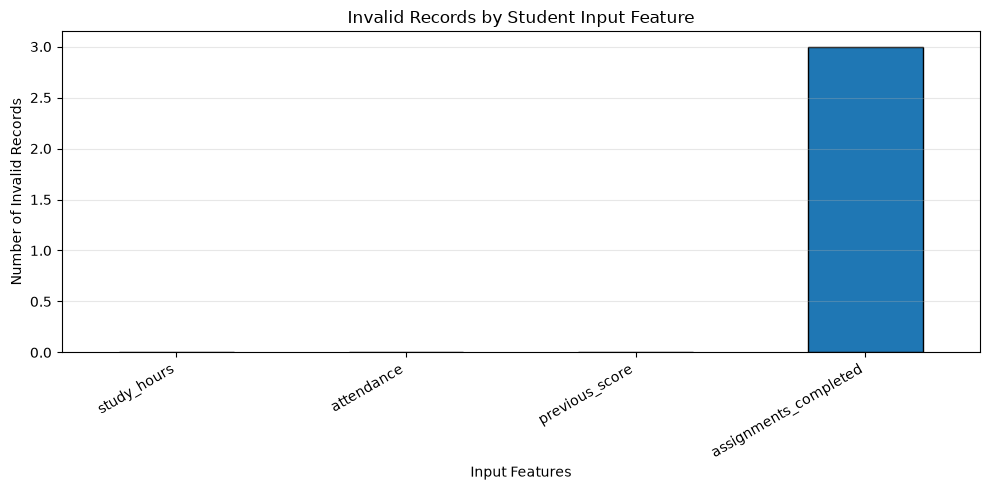

Total invalid feature-value counts: 3
Some invalid values were detected.
Review those records before further processing.


In [8]:
# Cell 8: Visualize Invalid Values

if "invalid_df" in globals() and not invalid_df.empty:

    print("=" * 55)
    print("INVALID VALUES VISUALIZATION")
    print("=" * 55)

    plt.figure(figsize=(10, 5))

    invalid_df["Invalid Record Count"].plot(
        kind="bar",
        edgecolor="black"
    )

    plt.title("Invalid Records by Student Input Feature")
    plt.xlabel("Input Features")
    plt.ylabel("Number of Invalid Records")
    plt.xticks(rotation=30, ha="right")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

    total_invalid_counts = invalid_df["Invalid Record Count"].sum()

    print("Total invalid feature-value counts:", int(total_invalid_counts))

    if total_invalid_counts == 0:
        print("No invalid values detected under the selected range rules.")
    else:
        print("Some invalid values were detected.")
        print("Review those records before further processing.")

else:
    print("invalid_df is unavailable. Please run Cell 7 first.")

In [9]:
# Cell 9: Create a Validated Dataset

if "X_validation" in globals() and not X_validation.empty:

    df_validated = X_validation.copy()

    # Identify rows containing missing values
    rows_with_missing = df_validated.isnull().any(axis=1)

    # Identify rows containing values outside expected ranges
    invalid_rows = pd.Series(False, index=df_validated.index)

    if "study_hours" in df_validated.columns:
        invalid_rows |= (
            (df_validated["study_hours"] < 0) |
            (df_validated["study_hours"] > 24)
        )

    if "attendance" in df_validated.columns:
        invalid_rows |= (
            (df_validated["attendance"] < 0) |
            (df_validated["attendance"] > 100)
        )

    if "previous_score" in df_validated.columns:
        invalid_rows |= (
            (df_validated["previous_score"] < 0) |
            (df_validated["previous_score"] > 100)
        )

    if "assignments_completed" in df_validated.columns:
        invalid_rows |= (
            (df_validated["assignments_completed"] < 0) |
            (df_validated["assignments_completed"] % 1 != 0)
        )

    # Combine missing and invalid-value checks
    rows_to_review = rows_with_missing | invalid_rows

    df_needs_review = df_validated.loc[rows_to_review].copy()
    df_reviewed_candidates = df_validated.loc[~rows_to_review].copy()

    print("=" * 55)
    print("VALIDATED DATASET SUMMARY")
    print("=" * 55)

    print("Total records:", len(df_validated))
    print("Records needing review:", len(df_needs_review))
    print("Records passing these checks:", len(df_reviewed_candidates))

    print("\nRecords needing review:")
    display(df_needs_review.head(10))

    print("\nRecords passing the selected checks:")
    display(df_reviewed_candidates.head(10))

    print("\nNote: These checks use the assumed ranges from Cell 7.")
    print("Passing these checks does not guarantee that every value is correct.")

else:
    print("X_validation is unavailable. Please run Cell 6 first.")

VALIDATED DATASET SUMMARY
Total records: 3
Records needing review: 3
Records passing these checks: 0

Records needing review:


,study_hours,attendance,previous_score,assignments_completed
0,6.4,91.0,57.6,8.71
1,4.2,85.5,37.8,8.82
2,4.8,87.0,43.2,8.51



Records passing the selected checks:


,study_hours,attendance,previous_score,assignments_completed



Note: These checks use the assumed ranges from Cell 7.
Passing these checks does not guarantee that every value is correct.


In [10]:
# Cell 10: Save Validated Dataset

if "df_reviewed_candidates" in globals():

    output_path = Path.cwd() / "day29_validated_student_features.csv"

    df_reviewed_candidates.to_csv(output_path, index=False)

    print("=" * 55)
    print("VALIDATED DATASET SAVED")
    print("=" * 55)

    print("Output file:", output_path.resolve())
    print("Total records saved:", len(df_reviewed_candidates))
    print("Total features:", len(df_reviewed_candidates.columns))

    print("\nSaved Dataset Preview:")
    display(df_reviewed_candidates.head())

    print("\nDataset export completed successfully!")

else:
    print("Validated dataset is unavailable.")
    print("Please run Cell 9 first.")

VALIDATED DATASET SAVED
Output file: C:\Users\Bagmita\OneDrive\Desktop\Project\day29_validated_student_features.csv
Total records saved: 0
Total features: 4

Saved Dataset Preview:


,study_hours,attendance,previous_score,assignments_completed



Dataset export completed successfully!


ORIGINAL VS VALIDATED DATA COMPARISON


,Category,Count
0,Original Records,3
1,Records Passing Checks,0
2,Records Needing Review,3


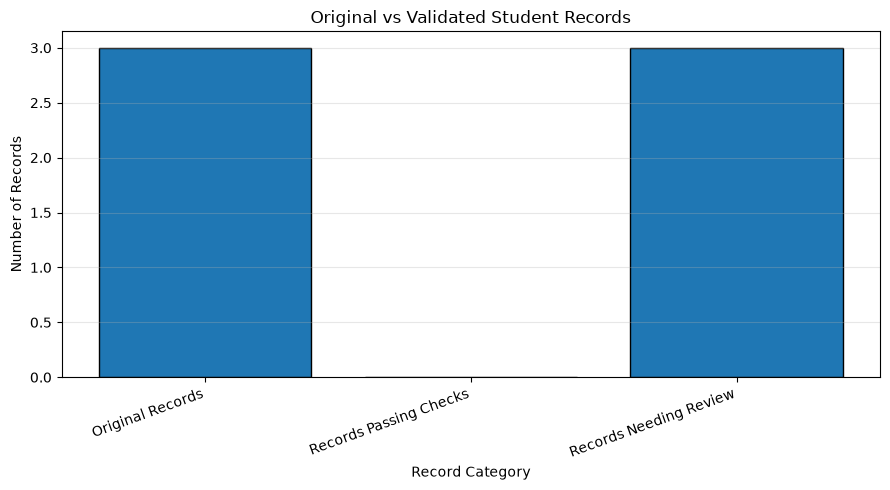

Records passing checks: 0.00%

Comparison completed successfully!


In [11]:
# Cell 11: Compare Original and Validated Data

if "df_unique" in globals() and "df_reviewed_candidates" in globals():

    original_records = len(df_unique)
    validated_records = len(df_reviewed_candidates)
    review_records = len(df_needs_review)

    comparison = pd.DataFrame({
        "Category": [
            "Original Records",
            "Records Passing Checks",
            "Records Needing Review"
        ],
        "Count": [
            original_records,
            validated_records,
            review_records
        ]
    })

    print("=" * 55)
    print("ORIGINAL VS VALIDATED DATA COMPARISON")
    print("=" * 55)

    display(comparison)

    plt.figure(figsize=(9, 5))
    plt.bar(
        comparison["Category"],
        comparison["Count"],
        edgecolor="black"
    )

    plt.title("Original vs Validated Student Records")
    plt.xlabel("Record Category")
    plt.ylabel("Number of Records")
    plt.xticks(rotation=20, ha="right")
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()

    if original_records > 0:
        retention_rate = validated_records / original_records * 100
        print(f"Records passing checks: {retention_rate:.2f}%")

    print("\nComparison completed successfully!")

else:
    print("Required datasets are unavailable.")
    print("Please run Cells 5 and 9 first.")

In [12]:
# Cell 12: Day 29 Final Data Quality Report

if (
    "df_unique" in globals()
    and "df_reviewed_candidates" in globals()
    and "df_needs_review" in globals()
):

    print("=" * 60)
    print("STUDENT PERFORMANCE PREDICTION SYSTEM")
    print("DAY 29 - FINAL DATA QUALITY REPORT")
    print("=" * 60)

    print("\n1. Dataset Summary")
    print("Original dataset records:", len(df))
    print("Records after exact duplicate removal:", len(df_unique))
    print("Records passing selected checks:", len(df_reviewed_candidates))
    print("Records needing review:", len(df_needs_review))

    print("\n2. Input Features Checked")
    print(df_reviewed_candidates.columns.tolist())

    print("\n3. Missing Values in Validated Dataset")
    display(df_reviewed_candidates.isnull().sum().to_frame(
        "Missing Values"
    ))

    print("\n4. Descriptive Statistics")
    display(df_reviewed_candidates.describe().round(2))

    print("\n5. Output File")
    output_path = Path.cwd() / "day29_validated_student_features.csv"
    print("Expected file:", output_path.resolve())
    print("File exists:", output_path.exists())

    print("\n6. Completion Status")
    print("Data quality checks completed.")
    print("Records needing review should be examined before use.")

    print("\nIMPORTANT:")
    print("These checks do not establish model accuracy.")
    print("Actual performance labels are needed for supervised training")
    print("and reliable evaluation.")

    print("\nDay 29 analysis completed!")
    print("=" * 60)

else:
    print("Required variables are unavailable.")
    print("Please run Cells 2, 5, 6, 9, and 10 first.")

STUDENT PERFORMANCE PREDICTION SYSTEM
DAY 29 - FINAL DATA QUALITY REPORT

1. Dataset Summary
Original dataset records: 3
Records after exact duplicate removal: 3
Records passing selected checks: 0
Records needing review: 3

2. Input Features Checked
['study_hours', 'attendance', 'previous_score', 'assignments_completed']

3. Missing Values in Validated Dataset


,Missing Values
study_hours,0
attendance,0
previous_score,0
assignments_completed,0



4. Descriptive Statistics


,study_hours,attendance,previous_score,assignments_completed
count,0.0,0.0,0.0,0.0
mean,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN
max,NaN,NaN,NaN,NaN



5. Output File
Expected file: C:\Users\Bagmita\OneDrive\Desktop\Project\day29_validated_student_features.csv
File exists: True

6. Completion Status
Data quality checks completed.
Records needing review should be examined before use.

IMPORTANT:
These checks do not establish model accuracy.
Actual performance labels are needed for supervised training
and reliable evaluation.

Day 29 analysis completed!
